# NyahMuk Model 1: breeding-object detector (baseline)
Train YOLOv8s on the cleaned VisText detection data (5 classes, unchanged), then test it on the held-out test split.
**Before you start:** Runtime > Change runtime type > **T4 GPU**. Run the cells top to bottom.

## Step 0. Check the GPU and install YOLO

In [1]:
!nvidia-smi
%pip -q install ultralytics

Sat Oct 17 03:00:22 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   37C    P8             11W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## Step 1. Mount Drive and set the configuration

In [2]:
import os, re, ast, json, random, shutil, zipfile
from pathlib import Path
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from PIL import Image
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass  # not running in Colab

# ---- paths ----
ZIP_CLEAN = Path('/content/drive/MyDrive/NyahMuk/clean_output/nyahmuk_clean_v2.zip')   # made by the fix cell
CLEAN = Path('/content/clean')                                                          # where it is unzipped
RUNS  = Path('/content/drive/MyDrive/NyahMuk/runs')                                     # results are saved on Drive
RUN_NAME = 'model1_vistext_det_v1'

# ---- training settings ----
MODEL = 'yolov8s.pt'   # small pretrained YOLOv8 (downloaded automatically)
EPOCHS = 50
IMGSZ = 640
BATCH = 16
PATIENCE = 15          # stop early if validation does not improve for 15 epochs
SEED = 42
ALLOW_CPU = False

HAS_GPU = torch.cuda.is_available()
DEVICE = 0 if HAS_GPU else 'cpu'
print('GPU:', torch.cuda.get_device_name(0) if HAS_GPU else 'NONE')
assert HAS_GPU or ALLOW_CPU, 'No GPU found. Runtime > Change runtime type > T4 GPU, then run again.'
RUNS.mkdir(parents=True, exist_ok=True)

Mounted at /content/drive
GPU: Tesla T4


## Step 2. Unzip the clean data and write the dataset file

In [3]:
if not (CLEAN / 'vistext_det').exists():
    assert ZIP_CLEAN.exists(), f'Not found: {ZIP_CLEAN}. Run the v2 fix cell first, or point ZIP_CLEAN at the v1 zip.'
    zipfile.ZipFile(ZIP_CLEAN).extractall(CLEAN)

src = (CLEAN / 'vistext_det' / 'data.yaml').read_text()
NAMES = ast.literal_eval(re.search(r'names:\s*(\[.*?\])', src).group(1))
YAML = Path('/content/model1_data.yaml')
YAML.write_text(f"path: {CLEAN / 'vistext_det'}\ntrain: train/images\nval: valid/images\ntest: test/images\nnc: {len(NAMES)}\nnames: {NAMES}\n")
print(YAML.read_text())

path: /content/clean/vistext_det
train: train/images
val: valid/images
test: test/images
nc: 5
names: ['Bottle', 'Coconut-Exocarp', 'Drain-Inlet', 'Tire', 'Vase']



## Step 3. Sanity check the data before training

In [4]:
rows, per_split = [], {}
for s in ['train', 'valid', 'test']:
    imgs = sorted((CLEAN / 'vistext_det' / s / 'images').glob('*'))
    lbls = sorted((CLEAN / 'vistext_det' / s / 'labels').glob('*.txt'))
    cnt = np.zeros(len(NAMES), dtype=int)
    for l in lbls:
        for ln in l.read_text().split('\n'):
            if ln.strip(): cnt[int(float(ln.split()[0]))] += 1
    per_split[s] = cnt
    rows.append(dict(split=s, images=len(imgs), label_files=len(lbls), boxes=int(cnt.sum())))
    assert len(imgs) == len(lbls), f'{s}: images and labels do not match'
display(pd.DataFrame(rows))
display(pd.DataFrame(per_split, index=NAMES).T)

,split,images,label_files,boxes
0,train,3710,3710,7874
1,valid,369,369,728
2,test,182,182,424


,Bottle,Coconut-Exocarp,Drain-Inlet,Tire,Vase
train,1177,1922,1136,1490,2149
valid,100,171,135,116,206
test,50,101,54,115,104


## Step 4. Train
The first run downloads the pretrained weights. Each epoch prints precision, recall and mAP on the **valid** split. Results and weights are saved to Drive after every epoch, so a disconnect does not lose them.

In [5]:
from ultralytics import YOLO
model = YOLO(MODEL)
results = model.train(
    data=str(YAML), epochs=EPOCHS, imgsz=IMGSZ, batch=BATCH, patience=PATIENCE,
    seed=SEED, device=DEVICE, project=str(RUNS), name=RUN_NAME, workers=2, plots=True,
)
RUN_DIR = Path(model.trainer.save_dir)
BEST = RUN_DIR / 'weights' / 'best.pt'
print('Run folder  :', RUN_DIR)
print('Best weights:', BEST)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.178 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/model1_data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, fre

**If Colab disconnects mid-training**, reconnect, run Steps 0 to 3, then run this cell instead of Step 4 (set the folder name to your run, it may end in a number):

In [ ]:
# from ultralytics import YOLO
# RUN_DIR = RUNS / 'model1_vistext_det_v1'
# YOLO(RUN_DIR / 'weights' / 'last.pt').train(resume=True)

## Step 5. Evaluate on valid and test

In [6]:
best = YOLO(BEST)

def evaluate(split):
    m = best.val(data=str(YAML), split=split, imgsz=IMGSZ, batch=BATCH, device=DEVICE,
                 project=str(RUNS), name=f'{RUN_NAME}_{split}', exist_ok=True, plots=True, verbose=False)
    per = []
    for i, c in enumerate(m.box.ap_class_index):
        p, r, ap50, ap = m.box.class_result(i)
        per.append({'class': m.names[int(c)], 'precision': p, 'recall': r, 'mAP50': ap50, 'mAP50-95': ap})
    overall = {'class': 'ALL', 'precision': m.box.mp, 'recall': m.box.mr, 'mAP50': m.box.map50, 'mAP50-95': m.box.map}
    return pd.DataFrame(per + [overall]).round(3), RUNS / f'{RUN_NAME}_{split}'

val_tbl,  val_dir  = evaluate('val')
test_tbl, test_dir = evaluate('test')
print('VALID split (used to pick the best epoch, so slightly optimistic):'); display(val_tbl)
print('TEST split (never used for training or picking, the honest score):'); display(test_tbl)
test_tbl.to_csv(RUNS / f'{RUN_NAME}_test_per_class.csv', index=False)

Ultralytics 8.4.178 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,127,519 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2375.3±855.5 MB/s, size: 92.1 KB)
val: Scanning /content/clean/vistext_det/valid/labels.cache... 369 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 369/369 110.5Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 24/24 3.5it/s 6.9s
                   all        369        728       0.91      0.865       0.91      0.705
Speed: 2.2ms preprocess, 10.6ms inference, 0.0ms loss, 1.7ms postprocess per image
Results saved to /content/drive/MyDrive/NyahMuk/runs/model1_vistext_det_v1_val
Ultralytics 8.4.178 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,127,519 parameters, 0 gradients, 28.4 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, r

,class,precision,recall,mAP50,mAP50-95
0,Bottle,0.900,0.900,0.919,0.727
1,Coconut-Exocarp,0.943,0.959,0.980,0.776
2,Drain-Inlet,0.955,0.874,0.947,0.631
3,Tire,0.915,0.828,0.865,0.721
4,Vase,0.839,0.762,0.836,0.672
5,ALL,0.910,0.865,0.910,0.705


TEST split (never used for training or picking, the honest score):


,class,precision,recall,mAP50,mAP50-95
0,Bottle,0.841,0.860,0.883,0.644
1,Coconut-Exocarp,0.924,0.950,0.989,0.793
2,Drain-Inlet,0.946,0.978,0.991,0.637
3,Tire,0.757,0.813,0.833,0.665
4,Vase,0.894,0.798,0.889,0.721
5,ALL,0.872,0.880,0.917,0.692


## Step 6. Look at the curves and the confusion matrix

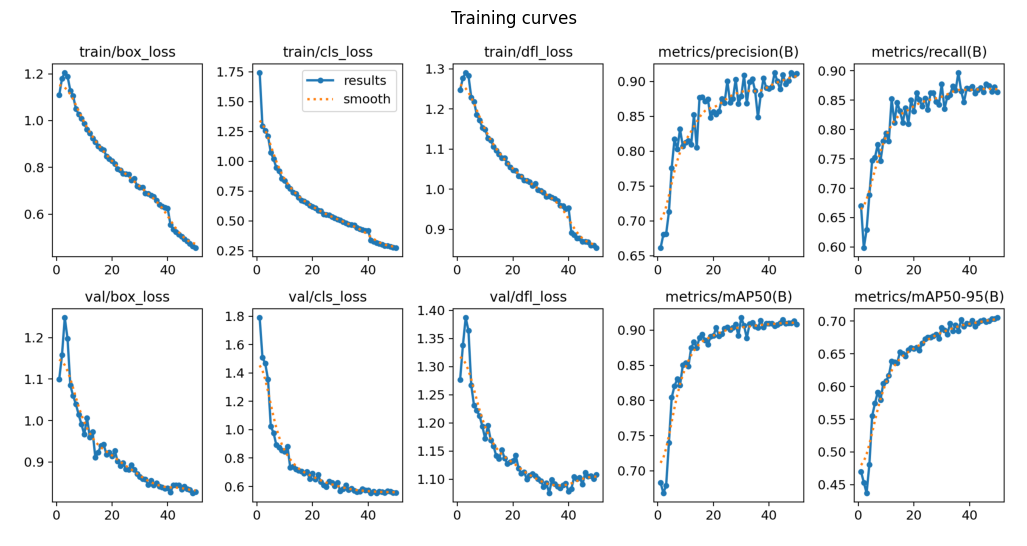

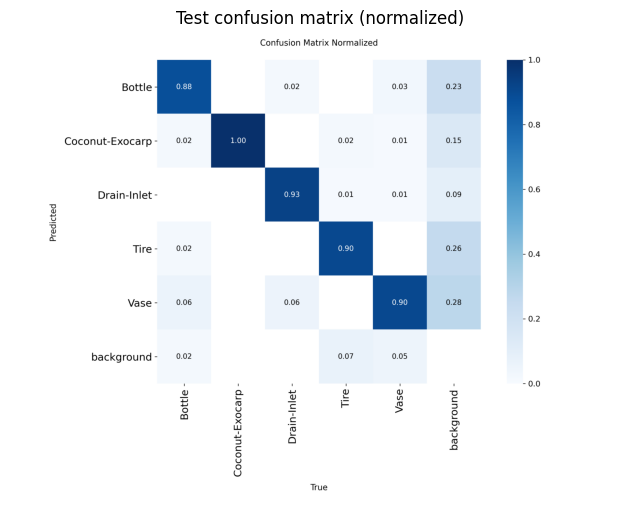

In [7]:
def show_img(path, title, size=(9, 6)):
    if Path(path).exists():
        plt.figure(figsize=size); plt.imshow(Image.open(path)); plt.axis('off'); plt.title(title); plt.show()
    else:
        print('missing:', path)

show_img(RUN_DIR / 'results.png', 'Training curves', (13, 7))
cm = next(iter(sorted(test_dir.glob('confusion_matrix*normalized*.png'))), None)
show_img(cm, 'Test confusion matrix (normalized)', (8, 7)) if cm else print('confusion matrix image not found in', test_dir)

## Step 7. Predictions on random test images

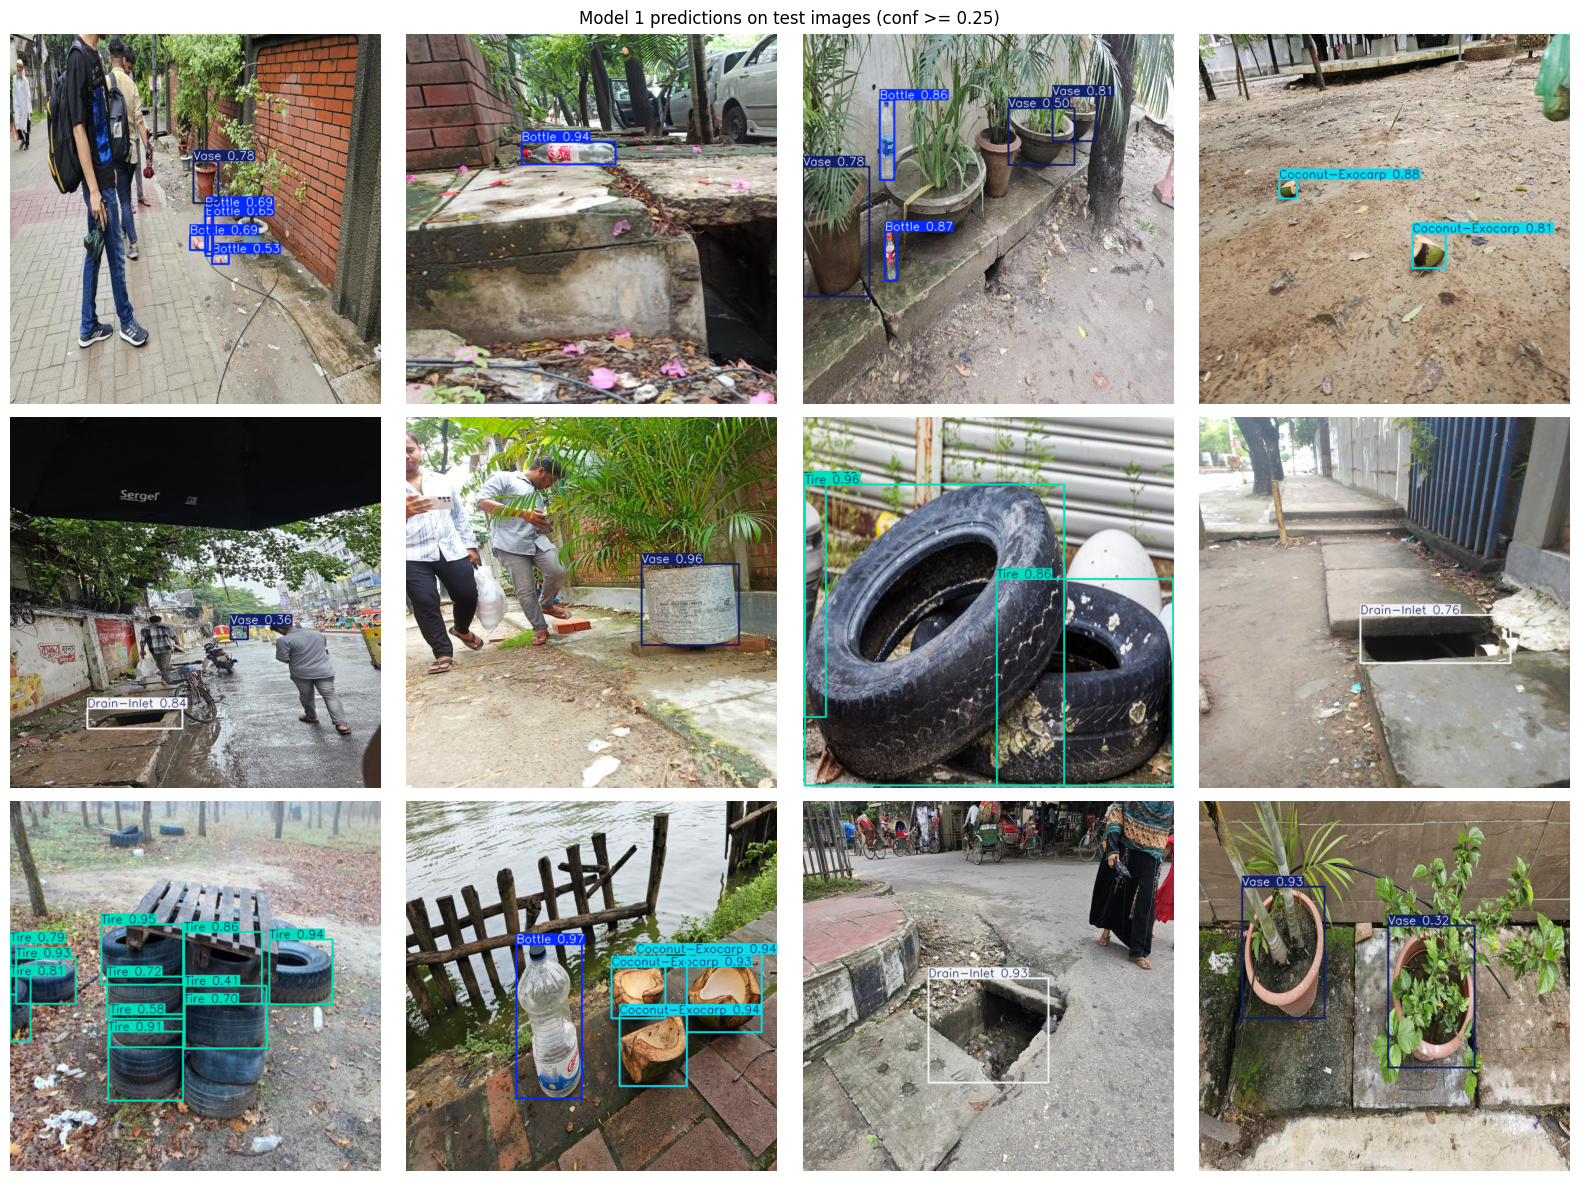

In [8]:
test_imgs = sorted((CLEAN / 'vistext_det' / 'test' / 'images').glob('*'))
sel = random.Random(1).sample(test_imgs, min(12, len(test_imgs)))
preds = best.predict([str(p) for p in sel], conf=0.25, imgsz=IMGSZ, device=DEVICE, verbose=False)
fig, axes = plt.subplots(3, 4, figsize=(16, 12))
for ax, r in zip(axes.flatten(), preds):
    ax.imshow(r.plot()[:, :, ::-1]); ax.axis('off')
plt.suptitle('Model 1 predictions on test images (conf >= 0.25)'); plt.tight_layout(); plt.show()

## Step 8. Save a summary

In [9]:
summary = dict(run=str(RUN_DIR), model=MODEL, epochs_requested=EPOCHS, imgsz=IMGSZ, batch=BATCH, seed=SEED,
               classes=NAMES, test=test_tbl.set_index('class').to_dict('index'), valid=val_tbl.set_index('class').to_dict('index'))
(RUNS / f'{RUN_NAME}_summary.json').write_text(json.dumps(summary, indent=2))
print('Saved summary to', RUNS / f'{RUN_NAME}_summary.json')
print('Best weights   :', BEST)

Saved summary to /content/drive/MyDrive/NyahMuk/runs/model1_vistext_det_v1_summary.json
Best weights   : /content/drive/MyDrive/NyahMuk/runs/model1_vistext_det_v1/weights/best.pt


## How to read the results
- **mAP50** is the main score (0 to 1): how well boxes overlap the true boxes at a loose 50% overlap. **mAP50-95** is stricter.
- **Recall** low = the model misses objects. **Precision** low = it draws boxes where nothing is.
- Compare **valid vs test**. A big drop on test means the model memorised valid-like photos.
- In the confusion matrix, look at the last column and row (background): objects predicted as nothing, or nothing predicted as an object.
- Expect weaker results on Drain-Inlet (one source) and on Bottle vs Coconut-Exocarp confusion. Send me the Step 5 tables and the confusion matrix and we decide the next fix from them.

##test my_photos

In [ ]:
#mount drive first
from ultralytics import YOLO
from pathlib import Path
import pandas as pd

BEST = '/content/drive/MyDrive/NyahMuk/runs/model1_vistext_det_v1/weights/best.pt'
PHOTOS = Path('/content/drive/MyDrive/NyahMuk/my_photos')
OUT = Path('/content/drive/MyDrive/NyahMuk/my_photos_predictions'); OUT.mkdir(exist_ok=True)

model = YOLO(BEST)
rows = []
for img in sorted(p for p in PHOTOS.rglob('*') if p.suffix.lower() in {'.jpg', '.jpeg', '.png'}):
    r = model.predict(str(img), conf=0.25, imgsz=640, verbose=False)[0]
    r.save(filename=str(OUT / f'{img.parent.name}__{img.name}'))
    found = [(r.names[int(c)], round(float(s), 2)) for c, s in zip(r.boxes.cls, r.boxes.conf)]
    rows.append(dict(folder=img.parent.name, file=img.name, n_boxes=len(found), found=found))
df = pd.DataFrame(rows); df.to_csv(OUT / 'predictions.csv', index=False); display(df)